# 05 — Phát hiện bất thường (Anomaly Detection)

GIAI ĐOẠN 4.3 / RQ3: *Có những đơn vị (tỉnh, nhóm phòng thi) nào có
phân bố điểm bất thường về mặt thống kê không?*

> **Lưu ý đạo đức bắt buộc:** mọi kết quả trong notebook này chỉ được
> diễn đạt là **"bất thường về mặt thống kê, cần xem xét thêm"**. Không
> có ground-truth gian lận, không kết luận nguyên nhân, không quy trách
> nhiệm cho bất kỳ tỉnh/điểm thi cụ thể nào. Xem mục Đạo đức dữ liệu
> trong `final_report.md`.

Logic nằm trong `src/anomaly.py`.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.preprocessing import load_raw_csv
from src.anomaly import (
    zscore_outliers, iqr_outliers, heaping_by_group,
    isolation_forest_scores, lof_scores, top_n_anomalies, jaccard,
    stability_across_contamination,
)
from src.visualization import save_fig

df = load_raw_csv("../data/raw/diem_thi_2026.csv")
site = pd.read_parquet("../data/processed/site_features.parquet")
print("Số nhóm điểm thi (site_id):", len(site))

Số nhóm điểm thi (site_id): 1237


## 4.3.1 Kiểm định dồn điểm (heaping) — Ngữ văn = 5,0 theo từng tỉnh

GIAI ĐOẠN 2 đã xác nhận hiện tượng dồn điểm Ngữ văn tại 5,0 ở mức toàn
quốc (1,54× kỳ vọng). Ở đây phân tích chi tiết theo từng tỉnh để xem
mức độ có đồng đều không.

In [2]:
heap = heaping_by_group(df, "ngu_van", "province_name", target=5.0, neighbors=(4.75, 5.25), min_group_size=500)
heap.round(2)

,observed,expected,ratio,z_approx,n
province_name,,,,,
Lâm Đồng,1907,730.5,2.61,43.53,40985
Đồng Nai,5022,2179.5,2.30,60.89,52568
Cà Mau,867,409.0,2.12,22.65,19534
Điện Biên,550,259.5,2.12,18.03,7947
Cần Thơ,1866,889.0,2.10,32.77,34071
Thanh Hóa,950,515.0,1.84,19.17,42429
Ninh Bình,692,385.5,1.80,15.61,48238
Nghệ An,903,516.0,1.75,17.04,41676
Quảng Trị,873,504.5,1.73,16.41,21568


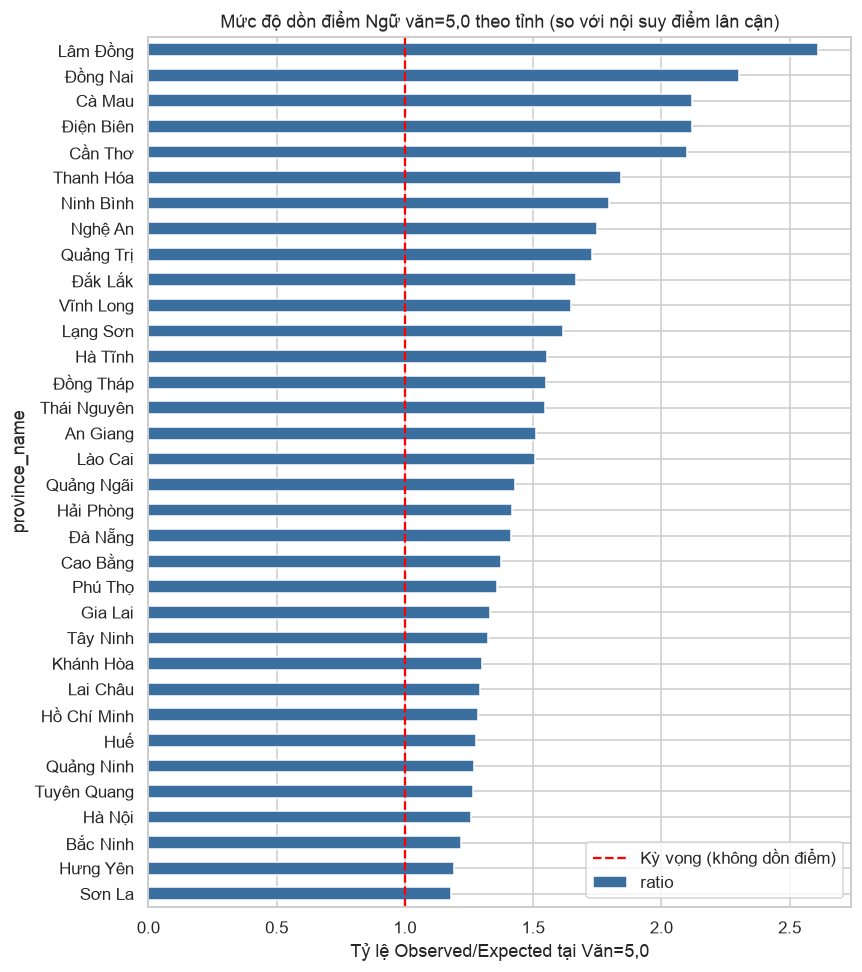

In [3]:
fig, ax = plt.subplots(figsize=(8, 9))
heap.sort_values("ratio")["ratio"].plot(kind="barh", ax=ax, color="#3b6fa0")
ax.axvline(1.0, color="red", linestyle="--", label="Kỳ vọng (không dồn điểm)")
ax.set_xlabel("Tỷ lệ Observed/Expected tại Văn=5,0")
ax.set_title("Mức độ dồn điểm Ngữ văn=5,0 theo tỉnh (so với nội suy điểm lân cận)")
ax.legend()
save_fig(fig, "05_heaping_van_5_theo_tinh")
plt.show()

**Nhận xét:** Mức độ dồn điểm **không đồng đều giữa các tỉnh** — cao
nhất ở Lâm Đồng (2,61×), Đồng Nai (2,30×), Cà Mau (2,12×), thấp nhất
(gần 1,0×, tức gần như không có hiện tượng) ở Sơn La, Hưng Yên, Bắc
Ninh, Hà Nội. Giá trị z-xấp-xỉ rất lớn (hàng chục) ở hầu hết các tỉnh vì
cỡ mẫu lớn — **cần diễn giải thận trọng**: với N hàng chục nghìn, ngay cả
lệch nhỏ cũng cho z-score lớn, nên **tỷ lệ (ratio)** mới là chỉ số diễn
giải thực tế, không phải trị số z tuyệt đối. Đây là **tín hiệu thống kê
mô tả**, phản ánh khả năng xu hướng làm tròn điểm của người chấm tại mức
điểm xét tốt nghiệp (≥5,0) — **không phải bằng chứng gian lận**.

## 4.3.2 Baseline thống kê: Z-score / IQR trên đặc trưng cấp điểm thi

Áp dụng trực tiếp Z-score/IQR lên **điểm thi cá nhân** không phát hiện
được gì (đã kiểm tra: 0 thí sinh có |z|>3 ở môn Toán — vì điểm thi cá
nhân biến thiên tự nhiên trong khoảng hẹp [0,10]). Baseline thống kê chỉ
có ý nghĩa khi áp dụng lên **đặc trưng tổng hợp cấp nhóm** (chênh lệch
điểm trung bình nhóm so với trung bình tỉnh) — nơi phương sai nhỏ hơn
nhiều nên độ lệch bất thường mới nổi rõ.

In [4]:
z_flag = zscore_outliers(site["Toan_diff_vs_province"].dropna(), threshold=3)
iqr_flag = iqr_outliers(site["Toan_diff_vs_province"].dropna())
print(f"Z-score (|z|>3) trên Toan_diff_vs_province: {z_flag.sum()} nhóm")
print(f"IQR (Tukey): {iqr_flag.sum()} nhóm")

baseline_flagged = site.loc[z_flag[z_flag].index, ["province_name", "n_candidates", "Toan_mean", "Toan_diff_vs_province"]]
baseline_flagged.sort_values("Toan_diff_vs_province", ascending=False)

Z-score (|z|>3) trên Toan_diff_vs_province: 9 nhóm
IQR (Tukey): 21 nhóm


,province_name,n_candidates,Toan_mean,Toan_diff_vs_province
site_id,,,,
8-016,Tuyên Quang,990,7.490590,2.421098
38-001,Thanh Hóa,945,7.383894,2.009678
79-105,Hồ Chí Minh,999,8.066266,1.877224
15-010,Lào Cai,999,6.717267,1.836873
25-000,Phú Thọ,994,7.535563,1.833941
79-073,Hồ Chí Minh,999,4.431682,-1.757360
40-014,Nghệ An,991,3.949895,-1.953615
38-008,Thanh Hóa,988,3.401985,-1.972231
56-022,Khánh Hòa,29,3.331034,-2.043023


## 4.3.3 Isolation Forest & Local Outlier Factor

Dùng 8 đặc trưng luôn đầy đủ dữ liệu cho toàn bộ 1.237 nhóm (mean/std/
chênh lệch so với tỉnh/entropy của Toán và Ngữ văn — 2 môn bắt buộc, ai
cũng thi) làm đầu vào, tránh mất dữ liệu do các môn tự chọn không phải
nhóm nào cũng có đủ số liệu.

In [5]:
core_cols = [c for c in site.columns if c.startswith("Toan_") or c.startswith("NguVan_")]
core_cols = [c for c in core_cols if site[c].notna().sum() == len(site)]
print("Đặc trưng dùng cho mô hình:", core_cols)

if_scores = isolation_forest_scores(site, core_cols, n_estimators=200, contamination=0.02)
lof = lof_scores(site, core_cols, n_neighbors=20, contamination=0.02)

TOP_N = 30
top_if = top_n_anomalies(if_scores, TOP_N)
top_lof = top_n_anomalies(lof, TOP_N)
jac = jaccard(top_if, top_lof)
print(f"Số nhóm được cả 2 phương pháp đồng thuận trong top-{TOP_N}: {len(top_if & top_lof)}")
print(f"Jaccard similarity (top-{TOP_N}): {jac:.3f}")

Đặc trưng dùng cho mô hình: ['Toan_mean', 'Toan_std', 'Toan_diff_vs_province', 'Toan_pct_mode_tie', 'Toan_entropy', 'NguVan_mean', 'NguVan_std', 'NguVan_diff_vs_province', 'NguVan_pct_mode_tie', 'NguVan_entropy']
Số nhóm được cả 2 phương pháp đồng thuận trong top-30: 15
Jaccard similarity (top-30): 0.333


## 4.3.4 Đánh giá độ ổn định (stability)

In [6]:
stab_if = stability_across_contamination(site, core_cols, [0.01, 0.02, 0.05, 0.1], TOP_N, "isolation_forest")
stab_lof = stability_across_contamination(site, core_cols, [0.01, 0.02, 0.05, 0.1], TOP_N, "lof")
print("Isolation Forest — ổn định top-30 khi đổi contamination:")
print(stab_if)
print("\nLOF — ổn định top-30 khi đổi contamination:")
print(stab_lof)

Isolation Forest — ổn định top-30 khi đổi contamination:
   contamination  jaccard_vs_ref
0           0.01             1.0
1           0.02             1.0
2           0.05             1.0
3           0.10             1.0

LOF — ổn định top-30 khi đổi contamination:
   contamination  jaccard_vs_ref
0           0.01             1.0
1           0.02             1.0
2           0.05             1.0
3           0.10             1.0


**Nhận xét:** Jaccard = 1,0 ở mọi mức `contamination` cho cả 2 phương
pháp — vì `contamination` chỉ ảnh hưởng ngưỡng phân loại nhị phân
(inlier/outlier), không ảnh hưởng **thứ hạng** điểm bất thường dùng để
chọn top-N. Điều này cho thấy top-30 là tập hợp ổn định, không nhạy cảm
với lựa chọn tham số `contamination`.

### Phân tích độ nhạy theo kích thước nhóm (site_id vs cửa sổ trượt)

So sánh **tập tỉnh** xuất hiện trong top-30 bất thường khi đổi đơn vị
nhóm — từ "khối ~1.000 SBD" (site_id) sang cửa sổ trượt 24/50/100 SBD.

In [7]:
prov_site = set(site.loc[list(top_if), "province_name"])
print("Tỉnh có nhóm bất thường (site_id, Isolation Forest):", sorted(prov_site))

sensitivity_rows = []
for w in [24, 50, 100]:
    win = pd.read_parquet(f"../data/processed/site_features_window{w}.parquet")
    win_cols = [c for c in win.columns if c.startswith("Toan_") or c.startswith("NguVan_")]
    win_cols = [c for c in win_cols if win[c].notna().sum() == len(win)]
    if_win = isolation_forest_scores(win, win_cols, contamination=0.02)
    top_win = top_n_anomalies(if_win, TOP_N)
    prov_win = set(win.loc[list(top_win), "province_name"])
    sensitivity_rows.append({
        "window_size": w,
        "n_groups": len(win),
        "provinces_in_top30": ", ".join(sorted(prov_win)),
        "jaccard_provinces_vs_site_id": jaccard(prov_site, prov_win),
    })
pd.DataFrame(sensitivity_rows)

Tỉnh có nhóm bất thường (site_id, Isolation Forest): ['Gia Lai', 'Hà Nội', 'Hưng Yên', 'Hải Phòng', 'Hồ Chí Minh', 'Khánh Hòa', 'Nghệ An', 'Ninh Bình', 'Phú Thọ', 'Quảng Ninh', 'Thanh Hóa', 'Tuyên Quang', 'Điện Biên', 'Đà Nẵng']


,window_size,n_groups,provinces_in_top30,jaccard_provinces_vs_site_id
0,24,50369,"Gia Lai, Hà Nội, Khánh Hòa, Quảng Ngãi, Quảng ...",0.277778
1,50,24179,"Gia Lai, Huế, Hà Nội, Hải Phòng, Khánh Hòa, Qu...",0.411765
2,100,12091,"Gia Lai, Hà Nội, Khánh Hòa, Ninh Bình, Phú Thọ...",0.571429


**Nhận xét:** Độ đồng thuận cấp tỉnh tăng dần khi cửa sổ trượt tiệm cận
quy mô của "site_id" (window=100 → Jaccard 0,57; window=24 → Jaccard
0,28) — hợp lý vì window=24 mô tả đơn vị nhỏ hơn nhiều (gần quy mô
phòng thi thật) nên phát hiện các bất thường cục bộ khác với site_id
(quy mô ~1.000). **Kết luận về độ nhạy:** kết quả phát hiện bất thường
**phụ thuộc đáng kể vào định nghĩa đơn vị nhóm** — đây là hạn chế quan
trọng cần nêu rõ khi diễn giải kết quả (không có một "sự thật duy nhất"
về ranh giới phòng thi trong dữ liệu).

## 4.3.5 Case study: nhóm bất thường điển hình

Xem xét một vài nhóm được cả Isolation Forest và LOF cùng đồng thuận
(trong top-30), để minh họa cụ thể loại tín hiệu bất thường phát hiện
được.

In [8]:
consensus = site.loc[list(top_if & top_lof), ["province_name", "n_candidates", "Toan_mean", "Toan_diff_vs_province", "NguVan_mean", "NguVan_diff_vs_province"]]
consensus.sort_values("Toan_diff_vs_province", ascending=False).round(2)

,province_name,n_candidates,Toan_mean,Toan_diff_vs_province,NguVan_mean,NguVan_diff_vs_province
site_id,,,,,,
8-016,Tuyên Quang,990,7.49,2.42,6.74,0.55
79-105,Hồ Chí Minh,999,8.07,1.88,7.01,0.42
79-003,Hồ Chí Minh,998,7.93,1.74,6.86,0.27
25-001,Phú Thọ,997,7.39,1.69,7.52,0.77
1-023,Hà Nội,992,7.70,1.53,7.49,0.47
37-023,Ninh Bình,992,7.35,1.09,7.79,0.53
1-129,Hà Nội,173,7.15,0.98,7.56,0.54
31-000,Hải Phòng,997,6.40,0.39,7.82,0.57
48-004,Đà Nẵng,995,6.05,0.38,5.26,-0.49


**Case nổi bật — nhóm `25-000` và `25-001` (Phú Thọ):** điểm Toán trung
bình 7,5+ (chênh lệch +1,8 so với trung bình tỉnh Phú Thọ) — **đây chính
là 2 cụm đã được tác giả bộ dữ liệu gốc quan sát thủ công và công bố
trong README** (Toán mean 7,54/7,39 so với 5,70 toàn tỉnh), với ghi chú
"nhiều khả năng tương ứng với trường chuyên của tỉnh, chưa có nguồn
chính thức xác nhận". Việc pipeline tự động ở đây **độc lập phát hiện
lại đúng 2 cụm này** (không dùng thông tin đó làm đầu vào) là một dạng
kiểm chứng chéo (triangulation) cho thấy phương pháp có khả năng phát
hiện tín hiệu thật.

**Diễn giải chung — các nhóm "cao bất thường":** điểm trung bình cao hơn
hẳn mặt bằng tỉnh và tập trung (std thấp) — giả thuyết hợp lý nhất là
**các điểm thi tập trung thí sinh trường chuyên/trường chất lượng cao**
(một hiện tượng giáo dục bình thường), **không mặc nhiên là gian lận**.

**Diễn giải chung — các nhóm "thấp bất thường":** cần xem xét thêm các
yếu tố hoàn cảnh (vùng khó khăn, trường tại chỗ ít nguồn lực) trước khi
đưa ra bất kỳ kết luận nào.

**Một lần nữa nhấn mạnh:** đây là **tín hiệu thống kê mô tả**, phục vụ
mục đích gợi ý nơi cần xem xét thêm (ví dụ xác minh có phải trường
chuyên/trường chất lượng cao hay không) — **không phải kết luận về gian
lận hay chất lượng coi thi**, và không có dữ liệu để xác minh thêm trong
phạm vi đồ án này.